In [1]:
from argparse import Namespace 
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import urllib.request

In [2]:
#Arguments 
args = Namespace (
    seed=1234, 
    
    data_file="titanic.csv",
    train_size=0.75,
    test_size=0.25,
    num_epochs=100,
    max_depth=4,
    min_samples_leaf=5,
    n_estimators=10, # of trees in the forest
) 

#set seed for reproducability 
np.random.seed(args.seed) 

In [3]:
# Download and load the dataset
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
urllib.request.urlretrieve(url, args.data_file)
raw_df = pd.read_csv(args.data_file)
raw_df.columns = raw_df.columns.str.lower()
display(raw_df.head())


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
from sklearn.tree import DecisionTreeClassifier 


In [5]:
# Preprocess a fresh copy of the loaded data
def preprocess(df):
    df = df.drop(columns=['name', 'cabin', 'ticket', 'passengerid']).copy()
    df = df.dropna().copy()
    df['sex'] = df['sex'].map({'female': 0, 'male': 1}).astype(int)
    df['embarked'] = df['embarked'].map({'S': 0, 'C': 1, 'Q': 2}).astype(int)
    return df


In [6]:
#preprocess the dataset 
df = preprocess(raw_df) 
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,1,22.0,1,0,7.2500,0
1,1,1,0,38.0,1,0,71.2833,1
2,1,3,0,26.0,0,0,7.9250,0
3,1,1,0,35.0,1,0,53.1000,0
4,0,3,1,35.0,0,0,8.0500,0


In [7]:
#split the data 
mask = np.random.rand(len(df)) < args.train_size 
train_df = df[mask] 
test_df = df[~mask]
print ("Train size: {0}, test size: {1}".format(len(train_df), 
                                                len(test_df)))

Train size: 529, test size: 183


In [8]:
#separate X and y 
X_train = train_df.drop(["survived"], axis=1) 
y_train = train_df["survived"]
X_test = test_df.drop(["survived"], axis=1) 
y_test = test_df["survived"]

In [9]:
#intialise the model
dtree = DecisionTreeClassifier(criterion="entropy", random_state=args.seed,
                               max_depth=args.max_depth,
                               min_samples_leaf=args.min_samples_leaf)

In [10]:
#training
dtree.fit(X_train, y_train) 

,criterion,'entropy'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1234
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [11]:
#predictions 
pred_train = dtree.predict(X_train) 
pred_test = dtree.predict(X_test) 

In [12]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support 

In [13]:
#accuracy
train_acc = accuracy_score(y_train, pred_train)
test_acc = accuracy_score(y_test, pred_test) 
print("train acc: {0:.2f}, test acc: {1:.2f}".format(train_acc, test_acc))

train acc: 0.84, test acc: 0.79


In [14]:
#calculate other evaluation metrics 
precision, recall, F1, _ = precision_recall_fscore_support(y_test, pred_test, average="binary") 
print("precision: {0:.2f}. recall: {1:.2f}, F1: {2:.2f}".format(precision, recall, F1))

precision: 0.87. recall: 0.59, F1: 0.70


In [15]:
#interpretation installation of necessary packages 
%pip install graphviz pydotplus 

Note: you may need to restart the kernel to use updated packages.


In [16]:
from io import StringIO
from IPython.display import Image 
from sklearn.tree import export_graphviz
import pydotplus 

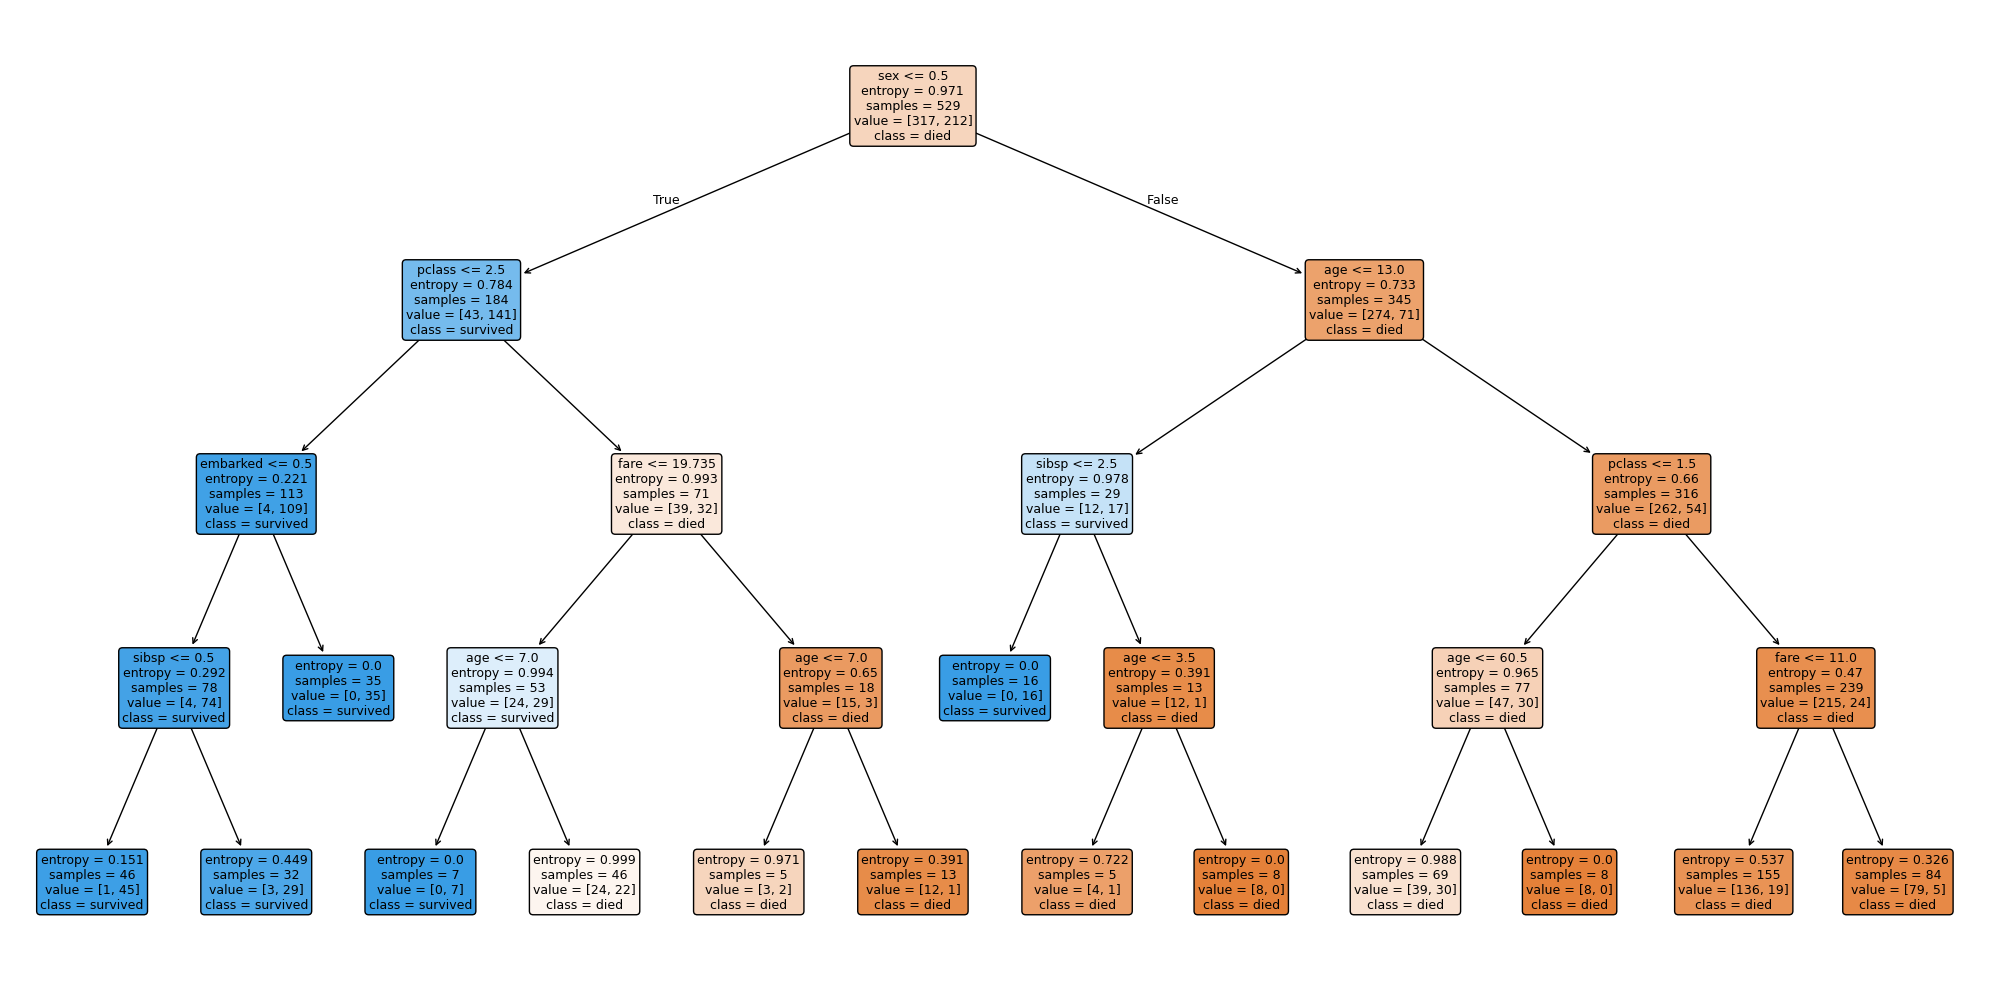

In [21]:
# Interpretability
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dtree,
    feature_names=list(train_df.drop(columns=["survived"]).columns),
    class_names=["died", "survived"],
    rounded=True,
    filled=True,
    fontsize=9
)

plt.tight_layout()
plt.show()

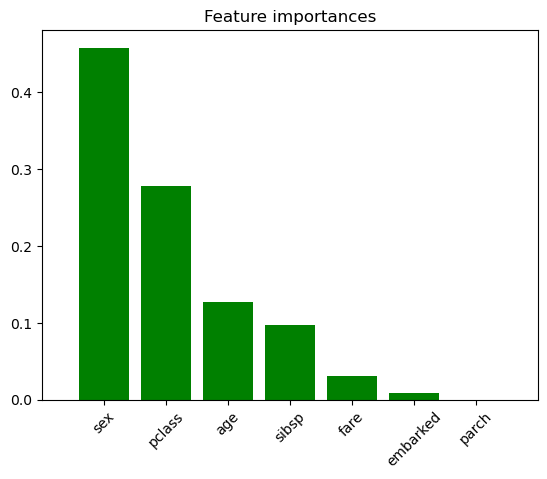

sex - 0.458
pclass - 0.278
age - 0.127
sibsp - 0.097
fare - 0.031
embarked - 0.009
parch - 0.000


In [23]:
#feature importances 
features = list(X_test.columns) 
importances = dtree.feature_importances_ 
indices = np.argsort(importances)[::-1]
num_features = len(importances) 

#plot the feature importances of the tree
plt.figure() 
plt.title("Feature importances") 
plt.bar(range(num_features), importances[indices], color="g", align="center") 
plt.xticks(range(num_features), [features[i] for i in indices], rotation=45) 
plt.xlim([-1, num_features]) 
plt.show() 

#print values 
for i in indices: 
    print ("{0} - {1:.3f}".format(features[i], importances[i]))

In [24]:
#scikit-learn implementation 
from sklearn.ensemble import RandomForestClassifier 

In [25]:
#initialise random forest 
forest = RandomForestClassifier(
    n_estimators=args.n_estimators, criterion="entropy", 
    max_depth=args.max_depth, min_samples_leaf=args.min_samples_leaf) 

In [26]:
#train 
forest.fit(X_train, y_train) 

,n_estimators,10
,criterion,'entropy'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
#predictions 
pred_train = forest.predict(X_train)
pred_test = forest.predict(X_test)

In [28]:
#accuracy 
train_acc = accuracy_score(y_train, pred_train) 
test_acc = accuracy_score(y_test, pred_test) 
print("train acc: {0:.2f}, test acc: {1:.2f}".format(train_acc, test_acc))

#calculate other evaluation metrics 
precision, recall, F1, _= precision_recall_fscore_support(y_test, pred_test, average="binary") 
print ("precision: {0:.2f}. recall: {1:.2f}, F1: {2:.2f}".format(precision, recall, F1))

train acc: 0.83, test acc: 0.77
precision: 0.84. recall: 0.55, F1: 0.67


In [ ]:
#Feature importances 
features = list(X_test.columns)
importances = forest.feature_importances_ 
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0) 
indices = np.argsort(importances)[::-1]
num_features = len(importances) 

#plot the feature importances of the tree 
plt.figure()
plt.title("Feature importances") 
plt.bar(range(num_features), importances[indices], yerr=std[indices],
        color="g", align="center